<a href="https://colab.research.google.com/github/romanotancredi/equity-investment-research-portfolio/blob/main/06_investment_review_and_recommendations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Phase 6 — Investment Review & Portfolio Recommendations

## Investment Objective

Evaluate the historical performance, risk characteristics
and regional positioning of a hypothetical global equity
portfolio relative to the Vanguard Total World Stock ETF (VT).

The analysis aims to identify key sources of relative
performance, evaluate portfolio risks and formulate
evidence-based investment recommendations.

### Portfolio Construction
- US equities (VTI): 60%
- Developed ex-US equities (VEA): 30%
- Emerging markets equities (VWO): 10%
- Benchmark: Vanguard Total World Stock ETF (VT)
- Rebalancing assumption: Daily


In [25]:

# ---------------------------------------------------------
# PHASE 6 - STEP 1: LOAD AND RECONSTRUCT PORTFOLIO RETURNS
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the same adjusted ETF prices used in previous phases.
url = (
    "https://raw.githubusercontent.com/romanotancredi/"
    "equity-investment-research-portfolio/refs/heads/main/"
    "01-equity-performance-and-risk/data/etf_prices.csv"
)

prices = pd.read_csv(
    url,
    index_col="Date",
    parse_dates=["Date"]
).sort_index()

# Calculate daily ETF returns.
daily_returns = prices.pct_change().dropna()

# Define the portfolio's constant target weights.
weights = pd.Series({
    "VTI": 0.60,
    "VEA": 0.30,
    "VWO": 0.10
})

# Reconstruct daily portfolio returns.
# This assumes daily rebalancing to target weights.
portfolio_returns = daily_returns[weights.index].dot(weights)

# Extract daily benchmark returns.
benchmark_returns = daily_returns["VT"]

# Combine both into one DataFrame.
performance = pd.DataFrame({
    "Portfolio": portfolio_returns,
    "Benchmark": benchmark_returns
})

# Calculate cumulative growth from a starting value of 100.
cumulative_performance = (1 + performance).cumprod() * 100

# Display the latest values.
display(cumulative_performance.tail())

,Portfolio,Benchmark
Date,,
2026-10-26,221.561105,218.158606
2026-10-27,223.042495,219.620986
2026-10-28,224.000169,220.456616
2026-10-29,223.629720,220.010951
2026-10-30,219.852348,216.334121


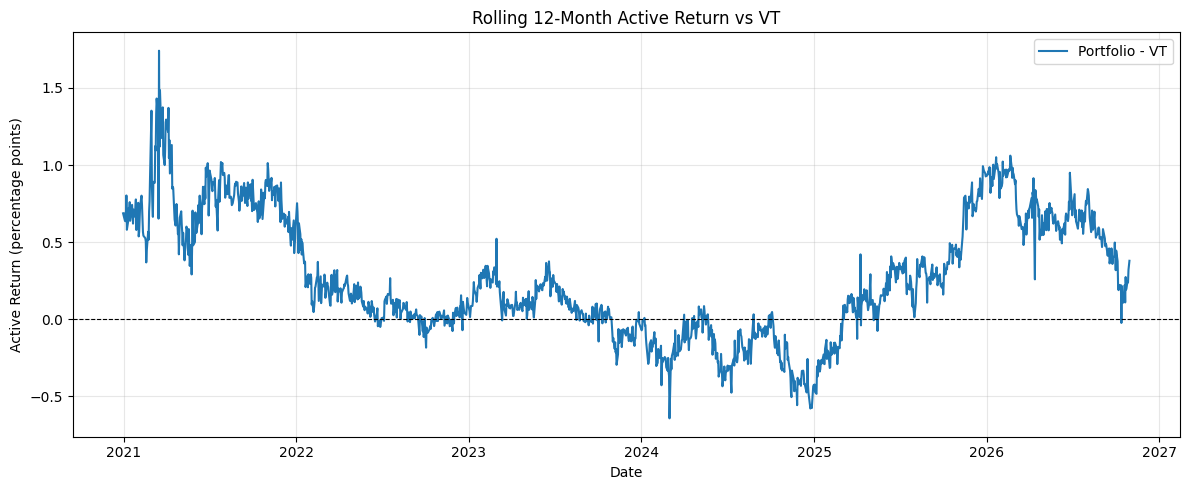

Positive rolling 12-month periods: 74.3%


In [26]:

# ---------------------------------------------------------
# PHASE 6 - STEP 2: ROLLING 12-MONTH RELATIVE PERFORMANCE
# ---------------------------------------------------------

# Define a standard 252-trading-day window.
window = 252

# Calculate compounded rolling 12-month returns.
rolling_returns = (
    (1 + performance)
    .rolling(window)
    .apply(np.prod, raw=True)
    - 1
)

# Calculate the rolling return difference.
# This is expressed in percentage points, not as
# a compounded portfolio/benchmark return ratio.
rolling_active_return = (
    rolling_returns["Portfolio"]
    - rolling_returns["Benchmark"]
) * 100

# Create the chart.
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    rolling_active_return.index,
    rolling_active_return,
    label="Portfolio - VT"
)

ax.axhline(0, color="black", linestyle="--", linewidth=0.8)

ax.set_title("Rolling 12-Month Active Return vs VT")
ax.set_xlabel("Date")
ax.set_ylabel("Active Return (percentage points)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Assess the consistency of outperformance.
valid_periods = rolling_active_return.dropna()

outperformance_frequency = (
    (valid_periods > 0).mean() * 100
)

print(
    f"Positive rolling 12-month periods: "
    f"{outperformance_frequency:.1f}%"
)


## Key Findings & Investment Interpretation

### Relative Performance Consistency

The portfolio outperformed VT in approximately 74% of rolling
12-month periods, although relative performance was not uniform.

Outperformance peaked in 2021, weakened through late 2023,
and recovered during 2025, highlighting sensitivity to
changing market conditions.

### Risk-Adjusted Performance

The portfolio generated a modest annualised return advantage
of approximately 0.27 percentage points, with tracking error
of 0.89% and an information ratio of approximately 0.28.

While the positive information ratio indicates favourable
historical risk-adjusted active performance, the relatively
small return advantage provides limited evidence that
deviating from the benchmark delivers meaningful economic
benefits after implementation costs.

### Portfolio Risk & Regional Exposure

The portfolio experienced substantial absolute drawdowns,
reflecting its exposure to global equity market risk.

US equities represented the largest portfolio allocation
and the strongest positive contributor to historical active
returns. However, this does not establish that an overweight
US position generated the outperformance.

A comparison with historical VT regional weights is required
to determine the magnitude and direction of active regional
exposures.

### Investment Recommendation

Maintain the existing 60/30/10 allocation as the baseline
for further analysis rather than immediately recommending
a regional reallocation.

Before implementing changes, assess historical benchmark
weights, regional concentration, turnover and transaction
costs, and the robustness of relative performance across
different market environments.

### Conclusion

The strategy demonstrated positive but modest historical
benchmark-relative performance, with a high proportion
of positive rolling 12-month observations.

However, the limited active return advantage and substantial
absolute equity risk do not yet establish a compelling case
for preferring the portfolio over a diversified global
equity benchmark.


,Maximum Drawdown (%),Trough Date
Portfolio,-34.35,2020-03-23
Benchmark,-34.24,2020-03-23


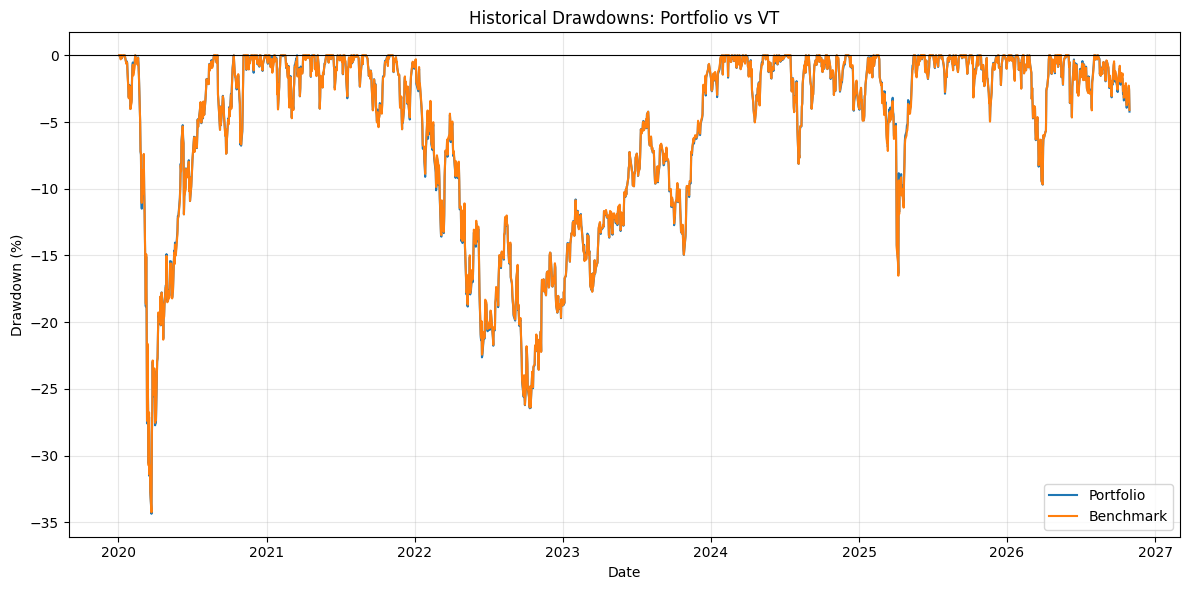

In [27]:

# ---------------------------------------------------------
# PHASE 6 - STEP 3: DRAWDOWN & DOWNSIDE RISK ANALYSIS
# ---------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate cumulative wealth starting from 100.
# cumprod() compounds the daily return observations.

wealth_index = (1 + performance).cumprod() * 100

# Calculate the previous historical peak in wealth.
# cummax() tracks the highest portfolio value reached.

running_peak = wealth_index.cummax()

# Calculate drawdowns relative to each series' peak.
# A drawdown of -0.20 represents a 20% decline.

drawdowns = wealth_index.div(running_peak) - 1

# Calculate maximum drawdown for each series.

max_drawdowns = drawdowns.min()

# Identify the dates of maximum drawdown.

max_drawdown_dates = drawdowns.idxmin()

# Summarise the results.

drawdown_summary = pd.DataFrame({
    "Maximum Drawdown (%)": max_drawdowns * 100,
    "Trough Date": max_drawdown_dates
})

display(drawdown_summary.round(2))

# ---------------------------------------------------------
# VISUALISATION
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

# Plot portfolio and benchmark drawdowns.

for column in drawdowns.columns:
    ax.plot(
        drawdowns.index,
        drawdowns[column] * 100,
        label=column
    )

ax.axhline(0, color="black", linewidth=0.8)

ax.set_title("Historical Drawdowns: Portfolio vs VT")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown (%)")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:

# ---------------------------------------------------------
# PHASE 6 - STEP 4: FINAL INVESTMENT SCORECARD
# ---------------------------------------------------------

# Number of daily return observations.
n = len(performance)

# Calculate annualised compounded returns (CAGR).
# The annualisation convention assumes 252 trading days.

annualised_return = (
    (1 + performance).prod() ** (252 / n) - 1
)

# Calculate annualised return volatility.

annualised_volatility = (
    performance.std() * np.sqrt(252)
)

# Calculate daily active returns.

active_returns = (
    performance["Portfolio"] - performance["Benchmark"]
)

# Annualised tracking error.

tracking_error = active_returns.std() * np.sqrt(252)

# Annualised arithmetic active return.

annualised_active_return = active_returns.mean() * 252

# Information ratio.

information_ratio = (
    annualised_active_return / tracking_error
)

# Build the scorecard.

scorecard = pd.DataFrame({
    "Portfolio": {
        "Annualised Return (%)":
            annualised_return["Portfolio"] * 100,
        "Annualised Volatility (%)":
            annualised_volatility["Portfolio"] * 100,
        "Maximum Drawdown (%)":
            max_drawdowns["Portfolio"] * 100
    },
    "VT Benchmark": {
        "Annualised Return (%)":
            annualised_return["Benchmark"] * 100,
        "Annualised Volatility (%)":
            annualised_volatility["Benchmark"] * 100,
        "Maximum Drawdown (%)":
            max_drawdowns["Benchmark"] * 100
    }
})

print("Investment Performance Scorecard")
display(scorecard.round(2))

print("\nActive Performance Metrics")
print(f"Tracking Error: {tracking_error:.2%}")
print(f"Information Ratio: {information_ratio:.3f}")
print(
    "Annualised Arithmetic Active Return:",
    f"{annualised_active_return:.2%}"
)

print(
    "Difference in Annualised Compounded Returns:",
    f"{(annualised_return['Portfolio'] - annualised_return['Benchmark']):.2%}"
)

Investment Performance Scorecard


,Portfolio,VT Benchmark
Annualised Return (%),12.26,12.00
Annualised Volatility (%),19.23,19.19
Maximum Drawdown (%),-34.35,-34.24



Active Performance Metrics
Tracking Error: 0.89%
Information Ratio: 0.273
Annualised Arithmetic Active Return: 0.24%
Difference in Annualised Compounded Returns: 0.27%



## Key Findings & Investment Recommendation

### Performance & Risk Assessment

The hypothetical global equity portfolio generated modest
historical outperformance relative to VT, with an annualised
return advantage of approximately 0.27 percentage points.

Tracking error of 0.89% indicates relatively limited
deviations from the benchmark, while an information ratio
of approximately 0.28 suggests modest risk-adjusted
active performance.

The portfolio outperformed VT in approximately 74% of
rolling 12-month observations, although relative returns
varied across market environments.

### Drawdown & Downside Risk

The portfolio experienced drawdowns broadly comparable
to those of VT, indicating similar exposure to global
equity market downturns.

Despite modest historical outperformance, the strategy
did not demonstrate a clear improvement in downside
protection relative to the benchmark.

Similar drawdowns and low tracking error suggest that
the portfolio's risk characteristics remain closely
aligned with those of a diversified global equity
investment strategy.

### Regional Allocation & Attribution

US equities (VTI) represented the largest positive
contributor to historical benchmark-relative returns.

However, the historical-weight attribution analysis
identified time-varying regional allocation effects,
including positive contributions from US and developed
ex-US positioning in 2025 and negative contributions
from US positioning in 2024.

The reconstructed regional benchmark exhibited tracking
error of 0.84% relative to VT, highlighting material
benchmark approximation risk.

Consequently, the estimated allocation effects cannot
fully explain historical outperformance, and the
benchmark reconstruction residual must be considered.

### Portfolio Implementation & Rebalancing

The strategy assumes daily rebalancing to constant
regional target weights of 60% VTI, 30% VEA and 10% VWO.

Although frequent rebalancing maintains portfolio
exposures, it may generate transaction costs and
turnover that reduce realised investment returns.

Given the relatively small historical return advantage,
implementation costs could materially affect the
economic attractiveness of the strategy.

Alternative rebalancing approaches, including monthly,
quarterly or tolerance-band rebalancing, should be
evaluated before implementation.

### Investment Recommendation

Maintain the existing 60/30/10 allocation as the
baseline for further research, rather than recommending
an immediate regional reallocation.

However, the current evidence does not establish a
compelling investment case for implementing the strategy
instead of a low-cost global equity benchmark such as VT.

Before implementation, further analysis should assess:

- Net-of-cost performance and portfolio turnover.
- Alternative rebalancing frequencies.
- Historical regional benchmark exposures.
- Sensitivity to different market environments.
- Robustness of risk-adjusted excess returns.

### Final Conclusion

The portfolio demonstrated positive but modest
benchmark-relative performance, with similar absolute
downside risk and relatively limited active risk.

While regional positioning contributed to historical
return differences, the magnitude and consistency of
outperformance do not yet justify a definitive
recommendation to deviate from VT.

From an investment committee perspective, maintaining
the strategy as a research baseline while prioritising
implementation-cost analysis represents the most
defensible course of action.

In [29]:

# ---------------------------------------------------------
# PHASE 6 - STEP 5A: REBALANCING SENSITIVITY ANALYSIS
# ---------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the daily ETF returns from the previous steps.
regional_returns = daily_returns[["VTI", "VEA", "VWO"]].copy()

# Define the target portfolio allocations.
target_weights = np.array([0.60, 0.30, 0.10])

def simulate_rebalancing(
    returns,
    frequency="Daily",
    cost_bps=0,
    threshold=0.05
):
    """
    Simulate portfolio performance using different
    rebalancing frequencies and transaction costs.

    cost_bps: Transaction cost per dollar traded.
    threshold: Maximum permitted absolute weight deviation.
    """

    # Start with the same allocation for all strategies.
    weights = target_weights.copy()

    # Store daily results.
    results = []

    previous_date = None

    for date, row in returns.iterrows():

        # Convert daily ETF returns into a NumPy array.
        asset_returns = row.to_numpy()

        # Determine whether rebalancing is required.
        rebalance = False

        if previous_date is not None:

            if frequency == "Daily":
                rebalance = True

            elif frequency == "Monthly":
                rebalance = (
                    date.to_period("M")
                    != previous_date.to_period("M")
                )

            elif frequency == "Quarterly":
                rebalance = (
                    date.to_period("Q")
                    != previous_date.to_period("Q")
                )

            elif frequency == "Threshold":
                rebalance = (
                    np.max(np.abs(weights - target_weights))
                    > threshold
                )

            else:
                raise ValueError("Unknown rebalancing frequency")

        # Calculate turnover and transaction costs.
        traded_notional = 0.0

        if rebalance:

            # Sum of absolute weight changes.
            # This measures total traded notional
            # relative to portfolio value.
            traded_notional = np.abs(
                target_weights - weights
            ).sum()

            # Rebalance to target allocations.
            weights = target_weights.copy()

        # Calculate transaction costs.
        trading_cost = (
            traded_notional * cost_bps / 10000
        )

        # Calculate portfolio return using weights
        # established before today's market return.
        gross_return = np.dot(weights, asset_returns)

        # Deduct trading costs before applying returns.
        net_return = (
            (1 - trading_cost) * (1 + gross_return) - 1
        )

        # Update asset weights after market movements.
        # The portfolio will drift until the next rebalance.
        weights = (
            weights * (1 + asset_returns)
            / (1 + gross_return)
        )

        # Store results.
        results.append({
            "Date": date,
            "Gross Return": gross_return,
            "Net Return": net_return,
            "Turnover": traded_notional / 2,
            "Rebalanced": int(rebalance and traded_notional > 0)
        })

        previous_date = date

    return pd.DataFrame(results).set_index("Date")


# Test different implementation costs.
frequencies = ["Daily", "Monthly", "Quarterly", "Threshold"]
cost_scenarios = [0, 5, 10, 20]

simulation_results = {}
summary_rows = []

for frequency in frequencies:

    for cost in cost_scenarios:

        result = simulate_rebalancing(
            regional_returns,
            frequency=frequency,
            cost_bps=cost
        )

        simulation_results[(frequency, cost)] = result

        # Calculate compounded annualised return.
        n = len(result)

        net_cagr = (
            (1 + result["Net Return"]).prod()
            ** (252 / n) - 1
        )

        # Calculate maximum drawdown.
        wealth = (1 + result["Net Return"]).cumprod()
        drawdown = wealth / wealth.cummax() - 1

        # Annualise one-way turnover.
        annual_turnover = (
            result["Turnover"].sum() * 252 / n
        )

        summary_rows.append({
            "Strategy": frequency,
            "Cost (bps)": cost,
            "Net CAGR (%)": net_cagr * 100,
            "Max Drawdown (%)": drawdown.min() * 100,
            "Annual Turnover (%)": annual_turnover * 100,
            "Rebalance Days": result["Rebalanced"].sum()
        })

sensitivity_summary = pd.DataFrame(summary_rows)

display(sensitivity_summary.round(2))

# Validate that the cost-free daily simulation matches
# our original constant-weight portfolio returns.
assert np.allclose(
    simulation_results[("Daily", 0)]["Gross Return"],
    portfolio_returns.loc[regional_returns.index]
)

print("Daily-rebalancing validation passed.")

,Strategy,Cost (bps),Net CAGR (%),Max Drawdown (%),Annual Turnover (%),Rebalance Days
0,Daily,0,12.26,-34.35,32.69,1715
1,Daily,5,12.23,-34.36,32.69,1715
2,Daily,10,12.19,-34.36,32.69,1715
3,Daily,20,12.12,-34.37,32.69,1715
4,Monthly,0,12.23,-34.39,6.51,81
5,Monthly,5,12.22,-34.39,6.51,81
6,Monthly,10,12.21,-34.39,6.51,81
7,Monthly,20,12.20,-34.39,6.51,81
8,Quarterly,0,12.20,-34.40,3.77,27
9,Quarterly,5,12.20,-34.40,3.77,27


Daily-rebalancing validation passed.


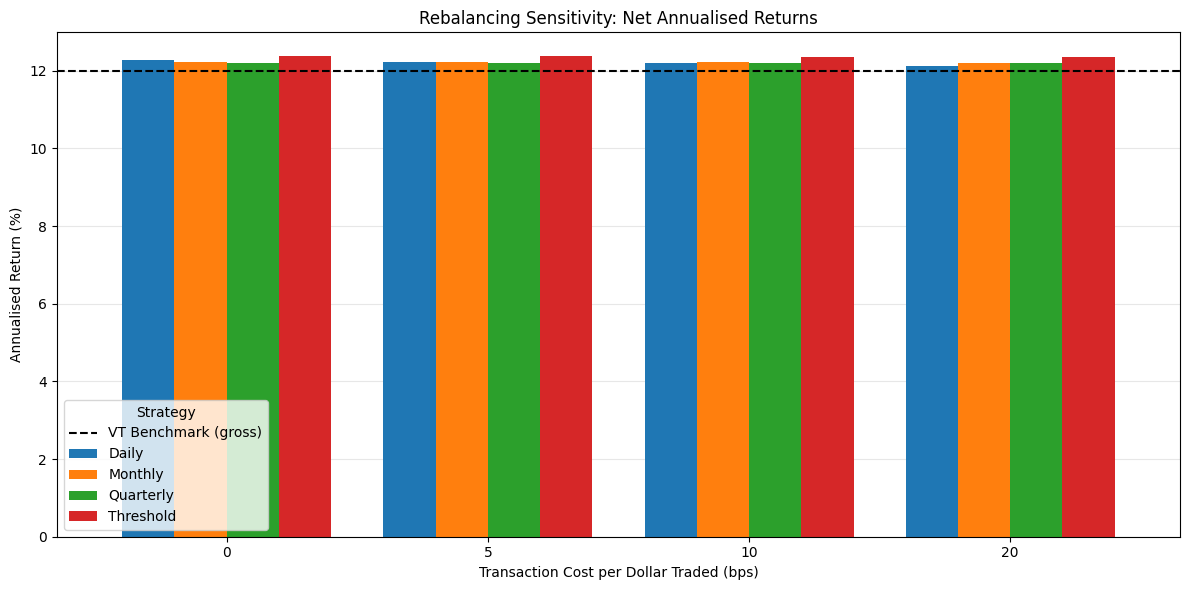

In [30]:

# ---------------------------------------------------------
# PHASE 6 - STEP 5B: NET PERFORMANCE SENSITIVITY CHART
# ---------------------------------------------------------

# Convert results into a matrix for visualisation.
chart_data = sensitivity_summary.pivot(
    index="Cost (bps)",
    columns="Strategy",
    values="Net CAGR (%)"
)

# Plot the results.
ax = chart_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

# Calculate the benchmark's annualised return.
benchmark_cagr = (
    (1 + performance["Benchmark"]).prod()
    ** (252 / len(performance)) - 1
) * 100

# Add VT's annualised return as a reference.
ax.axhline(
    benchmark_cagr,
    color="black",
    linestyle="--",
    label="VT Benchmark (gross)"
)

ax.set_title(
    "Rebalancing Sensitivity: Net Annualised Returns")


ax.set_xlabel("Transaction Cost per Dollar Traded (bps)")
ax.set_ylabel("Annualised Return (%)")

ax.legend(title="Strategy")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:

# ---------------------------------------------------------
# PHASE 6 - STEP 5C: TURNOVER & INFORMATION RATIO
# ---------------------------------------------------------

# Select one illustrative cost scenario: 10 bps.
cost_assumption = 10

comparison = []

benchmark = performance["Benchmark"].loc[
    regional_returns.index
]

for frequency in frequencies:

    result = simulation_results[
        (frequency, cost_assumption)
    ]

    net_returns = result["Net Return"]

    # Calculate daily active returns against VT.
    active = net_returns - benchmark

    # Annualised tracking error.
    te = active.std() * np.sqrt(252)

    # Information ratio based on arithmetic active return.
    ir = active.mean() * 252 / te

    # Calculate compounded annualised return.
    cagr = (
        (1 + net_returns).prod()
        ** (252 / len(net_returns)) - 1
    )

    comparison.append({
        "Strategy": frequency,
        "Net CAGR (%)": cagr * 100,
        "Tracking Error (%)": te * 100,
        "Information Ratio": ir,
        "Annual Turnover (%)":
            result["Turnover"].sum()
            * 252 / len(result) * 100
    })

comparison = pd.DataFrame(comparison).set_index("Strategy")

print("Rebalancing Comparison — 10 bps per Dollar Traded")
display(comparison.round(3))

Rebalancing Comparison — 10 bps per Dollar Traded


,Net CAGR (%),Tracking Error (%),Information Ratio,Annual Turnover (%)
Strategy,,,,
Daily,12.191,0.890,0.199,32.694
Monthly,12.210,0.887,0.219,6.509
Quarterly,12.195,0.894,0.204,3.773
Threshold,12.363,0.910,0.363,2.223



## Rebalancing Sensitivity Analysis — Key Findings

### Performance Before Transaction Costs

Daily rebalancing generated slightly higher compounded
returns than monthly and quarterly rebalancing before
transaction costs.

However, the magnitude of the performance advantage
was relatively limited.

### Impact of Transaction Costs

Introducing transaction costs reduced net returns across
all rebalancing strategies, with daily rebalancing
experiencing the greatest deterioration.

Less frequent rebalancing generally resulted in lower
portfolio turnover and implementation costs.

The performance differences became more pronounced
under higher transaction-cost assumptions, highlighting
the importance of implementation efficiency.

### Risk-Adjusted Performance

The 5-percentage-point threshold-based strategy generated
the highest net information ratio among the tested
approaches.

This suggests that tolerance-band rebalancing may offer
a more efficient balance between controlling portfolio
weight drift and limiting unnecessary transactions.

However, the results depend on the selected tolerance
band and historical market conditions.

### Investment Implications

Given the portfolio's modest historical outperformance
relative to VT, transaction costs represent an important
consideration in assessing the economic value of the
strategy.

The analysis indicates that maintaining constant target
weights through daily rebalancing may not provide
sufficient additional benefits to offset the associated
implementation costs.

### Recommendation

Maintain the 60/30/10 target allocation as the research
baseline while favouring threshold-based rebalancing
for further evaluation.

Before implementation, test alternative tolerance bands,
account for realistic trading costs and assess whether
the strategy's net risk-adjusted advantage persists
across different market environments.